In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [2]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [3]:
df = pd.read_csv("emails.csv", encoding="ISO-8859-1")

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nFirst Five Records:")
display(df.head())

Dataset Shape: (5172, 3002)

Column Names:
Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='object', length=3002)

First Five Records:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [4]:
if "Email No." in df.columns:
    df = df.drop(columns=["Email No."])

df["Prediction"] = pd.to_numeric(df["Prediction"], errors="coerce")

df.dropna(subset=["Prediction"], inplace=True)

df["Prediction"] = df["Prediction"].astype(int)

X = df.drop(columns=["Prediction"])
y = df["Prediction"]

X = X.fillna(0)

print("Missing Values:", X.isnull().sum().sum())

print("\nTarget Class Distribution:")
print(y.value_counts())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Missing Values: 0

Target Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64

Features Shape: (5172, 3000)
Target Shape: (5172,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 4137
Testing Records: 1035


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed.")

Feature Scaling Completed.


In [7]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print("KNN Classification Results")

print("\nAccuracy:", accuracy_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn, labels=[0, 1]))

KNN Classification Results

Accuracy: 0.8338164251207729

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


Confusion Matrix:
[[576 159]
 [ 13 287]]


In [8]:
svm = SVC(kernel="linear", random_state=42)

svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)

print("SVM Classification Results")

print("\nAccuracy:", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm, labels=[0, 1]))

SVM Classification Results

Accuracy: 0.9507246376811594

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035


Confusion Matrix:
[[709  26]
 [ 25 275]]


In [9]:
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],
    "Precision": [
        precision_score(y_test, y_pred_knn, zero_division=0),
        precision_score(y_test, y_pred_svm, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_knn, zero_division=0),
        recall_score(y_test, y_pred_svm, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_knn, zero_division=0),
        f1_score(y_test, y_pred_svm, zero_division=0)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.8338,0.6435,0.9567,0.7694
1,SVM,0.9507,0.9136,0.9167,0.9151


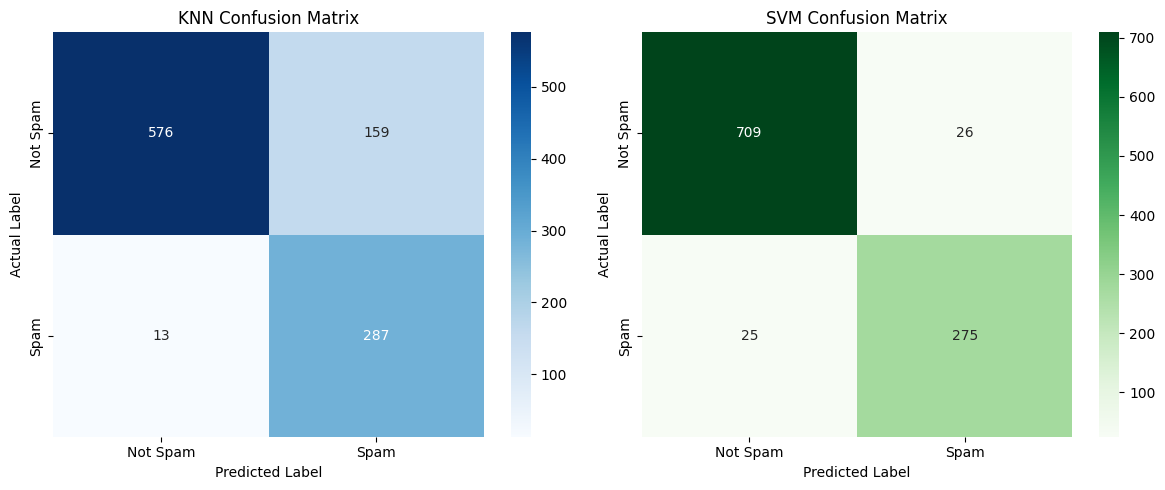

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_knn, labels=[0, 1]),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax[0]
)

ax[0].set_title("KNN Confusion Matrix")
ax[0].set_xlabel("Predicted Label")
ax[0].set_ylabel("Actual Label")
ax[0].set_xticklabels(["Not Spam", "Spam"])
ax[0].set_yticklabels(["Not Spam", "Spam"])

sns.heatmap(
    confusion_matrix(y_test, y_pred_svm, labels=[0, 1]),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=ax[1]
)

ax[1].set_title("SVM Confusion Matrix")
ax[1].set_xlabel("Predicted Label")
ax[1].set_ylabel("Actual Label")
ax[1].set_xticklabels(["Not Spam", "Spam"])
ax[1].set_yticklabels(["Not Spam", "Spam"])

plt.tight_layout()
plt.show()

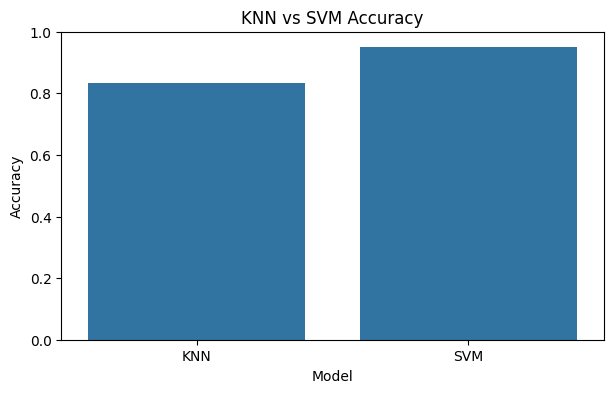

In [11]:
plt.figure(figsize=(7, 4))

sns.barplot(data=results, x="Model", y="Accuracy")

plt.title("KNN vs SVM Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()